# CNN TensorFlow/Keras — validation croisée 3 folds

Ce notebook remplace l'ancien entraînement PyTorch (split 70/15/15) par un CNN
**TensorFlow/Keras** évalué avec **3 folds au niveau enregistrement**. Pour chaque pli :

- entraînement sur 2 folds, validation sur le fold restant ;
- courbes `loss` et `accuracy`/`AUC` par epoch, sauvegardées en PNG et CSV ;
- métriques du pli, puis agrégation des prédictions *out-of-fold* pour choisir le seuil.

Pour rester entraînable sur CPU, les Mel 128×256 sont réduits à **64×128** (même downsample à l'inférence, voir `best_cnn_meta.json`).

Les plis sont exactement les mêmes que ceux de `SVM.ipynb` et `Decisiontree.ipynb`
(`KFold(3, shuffle=True, random_state=10)` sur les fichiers triés de chaque classe).


## 1. Imports et configuration

In [1]:
import json
import os
import random
import sys
import time
from datetime import datetime
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

# --- localisation du dépôt AVANT les imports locaux
DATA_ROOT = next((p / "ourdataset" / "train" for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "ourdataset" / "train").is_dir()), None)
assert DATA_ROOT is not None, f"ourdataset/train introuvable depuis {Path.cwd()}"
AUDIO_ENGINE_DIR = DATA_ROOT.parent.parent / "audio_engine"
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
assert (AUDIO_ENGINE_DIR / "preprocess.py").exists(), f"preprocess.py introuvable dans {AUDIO_ENGINE_DIR}"

import librosa
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

from preprocess import AudioError, Preprocessor
from fold_utils import (build_3fold_recording_splits, plot_all_folds_training,
                        plot_training_history, save_history_csv)
from src.dataset import KerasMelSequence

MODEL_DIR = AUDIO_ENGINE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
PLOT_DIR = MODEL_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)

# --- mêmes paramètres Mel que registry.py et l'ancien notebook
SR, N_MELS, N_FFT, HOP, T = 2000, 128, 512, 128, 256
DOWN = 2   # sous-échantillonnage CPU : 128×256 -> 64×128
INPUT_H, INPUT_W = N_MELS // DOWN, T // DOWN
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.backend.set_floatx("float32")

def configure_tensorflow_gpu():
    """Active le GPU TensorFlow (croissance mémoire) et affiche le diagnostic."""
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        for gpu in gpus:
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except Exception as exc:
                print(f"  mémoire dynamique indisponible pour {gpu}: {exc}")
        try:
            # Limite TensorFlow aux GPU détectés (évite certains conflits de devices).
            tf.config.set_visible_devices(gpus, "GPU")
        except Exception:
            pass
    build = {}
    try:
        build = tf.sysconfig.get_build_info()
    except Exception:
        pass
    cuda_build = build.get("is_cuda_build", build.get("cuda_version") is not None)
    print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
    print("Build CUDA :", cuda_build, "| CUDA", build.get("cuda_version"), "| cuDNN", build.get("cudnn_version"))
    if gpus:
        logical = []
        try:
            logical = tf.config.list_logical_devices("GPU")
        except Exception:
            logical = gpus
        print("GPU détecté(s) :", [d.name for d in logical], "-> entraînement sur GPU")
    else:
        print("GPU : aucun détecté -> entraînement sur CPU")
        if sys.platform.startswith("win"):
            print("  Note: sur Windows natif, TensorFlow >= 2.11 ne supporte pas le GPU NVIDIA.")
            print("  -> Utiliser WSL2 avec un environnement Linux et installer tensorflow[and-cuda]")
            print("     (voir requirements-train.txt), avec un pilote NVIDIA compatible.")


configure_tensorflow_gpu()

MEL_CACHE = MODEL_DIR / "tp3_cnn_mels_64x128.npy"          # spectrogrammes float16 (mmap)
INDEX_CACHE = MODEL_DIR / "tp3_cnn_mels_index.npz"  # clés "classe/nom.wav" + labels

pre = Preprocessor({"max_segments": 10})


def mel(seg):
    """Mel 128×256 dB normalisé, puis réduit à 64×128 (même traitement à l'inférence)."""
    m = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=20, fmax=SR // 2)
    m = librosa.power_to_db(m, ref=np.max)
    m = np.pad(m, ((0, 0), (0, max(0, T - m.shape[1]))))[:, :T].astype(np.float32)
    m = (m - m.mean()) / (m.std() + 1e-6)
    return m[::DOWN, ::DOWN]


TensorFlow 2.20.0 | Keras 3.12.4
Build CUDA : False | CUDA None | cuDNN None
GPU : aucun détecté -> entraînement sur CPU
  Note: sur Windows natif, TensorFlow >= 2.11 ne supporte pas le GPU NVIDIA.
  -> Utiliser WSL2 avec un environnement Linux et installer tensorflow[and-cuda]
     (voir requirements-train.txt), avec un pilote NVIDIA compatible.


## 2. Cache des spectrogrammes Mel

In [2]:
import sys
import tensorflow as tf

print(sys.executable)
print(tf.test.is_built_with_cuda())
print(tf.config.list_physical_devices("GPU"))

c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe
False
[]


In [3]:
files = [(p, label) for label, name in enumerate(["normal", "abnormal"])
         for p in sorted((DATA_ROOT / name).glob("*.wav"))]
print(len(files), "fichiers WAV")


def build_mel_cache(force=False):
    """Spectrogrammes de tous les segments (float16 sur disque, rechargés en mmap)."""
    if MEL_CACHE.exists() and INDEX_CACHE.exists() and not force:
        index = np.load(INDEX_CACHE, allow_pickle=True)
        X = np.load(MEL_CACHE, mmap_mode="r")
        print(f"Cache réutilisé : {MEL_CACHE.name} {X.shape} ({X.nbytes / 1e9:.2f} Go, mmap)")
        return X, index["keys"], index["y"].astype(np.int64)

    t0, keys, labels, blocks = time.time(), [], [], []
    for n, (path, label) in enumerate(files, start=1):
        try:
            segments = pre.segment(pre.load_clean(path.read_bytes()))
        except AudioError as error:
            print(f"  ignoré {path.name}: {error}")
            continue
        # float16 : 2× moins de RAM qu'un float32 puis conversion par lot à l'entraînement
        blocks.append(np.stack([mel(s) for s in segments]).astype(np.float16))
        keys += [f"{label}/{path.name}"] * len(segments)
        labels += [label] * len(segments)
        if n % 500 == 0:
            print(f"  {n}/{len(files)} fichiers, {sum(len(b) for b in blocks)} segments "
                  f"({time.time() - t0:.0f} s)")

    X_all = np.concatenate(blocks).astype(np.float16)
    X_all = X_all[:, None, :, :]                      # (N, 1, 128, 256)
    keys_all = np.array(keys, dtype=object)
    y_all = np.array(labels, dtype=np.int64)
    np.save(MEL_CACHE, X_all)
    np.savez(INDEX_CACHE, keys=keys_all, y=y_all)
    print(f"Cache écrit : {MEL_CACHE.name} {X_all.shape} ({X_all.nbytes / 1e9:.2f} Go) "
          f"en {(time.time() - t0) / 60:.1f} min")
    return X_all, keys_all, y_all


X_mel, keys_all, y_all = build_mel_cache()
print(f"{len(y_all)} segments pour {len(np.unique(keys_all))} enregistrements | "
      f"abnormal = {y_all.mean():.1%} des segments")


3784 fichiers WAV
Cache réutilisé : tp3_cnn_mels_64x128.npy (22126, 1, 64, 128) (0.36 Go, mmap)
22126 segments pour 3781 enregistrements | abnormal = 23.3% des segments


## 3. Découpage en 3 folds (au niveau enregistrement)

Les segments d'un même WAV restent dans le même pli : sinon des segments quasi identiques
d'un même enregistrement se retrouveraient en entraînement et en validation (fuite de données).


In [4]:
folds, recording_keys = build_3fold_recording_splits(keys_all, n_splits=3, seed=10)

for fold in folds:
    pos_tr, pos_va = fold["train_pos"], fold["test_pos"]
    print(f"pli {fold['fold']} : {len(fold['train_keys']):>4} WAV / {len(pos_tr):>5} segments "
          f"en train | {len(fold['test_keys']):>3} WAV / {len(pos_va):>4} segments en validation "
          f"(abnormal train={y_all[pos_tr].mean():.1%}, val={y_all[pos_va].mean():.1%})")


pli 1 : 2520 WAV / 14740 segments en train | 1261 WAV / 7386 segments en validation (abnormal train=23.4%, val=23.1%)
pli 2 : 2521 WAV / 14962 segments en train | 1260 WAV / 7164 segments en validation (abnormal train=23.2%, val=23.4%)
pli 3 : 2521 WAV / 14550 segments en train | 1260 WAV / 7576 segments en validation (abnormal train=23.3%, val=23.4%)


## 4. Modèle CNN TensorFlow/Keras

L'architecture vit dans `src/model_cnn_lite.py` (`build_cnn_lite`) : elle est importable par
le service d'inférence et sérialisable en `.keras`.


In [5]:
from src.model_cnn_lite import build_cnn_lite

model = build_cnn_lite(n_classes=2, dropout=0.3, input_shape=(INPUT_H, INPUT_W, 1))
model.summary()
n_params = int(model.count_params())
print(f"{n_params:,} paramètres".replace(",", " "))


Model: "cardio_cnn_lite"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mel_input (InputLayer)          │ (None, 64, 128, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 128, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 16, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 16, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 16, 256)     │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 16, 256)     │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 16, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 128)            │             

 Total params: 422,434 (1.61 MB)

 Trainable params: 421,474 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

422 434 paramètres


## 5. Entraînement des 3 folds

- perte `SparseCategoricalCrossentropy` pondérée par les classes (déséquilibre ≈ 77/23) ;
- early stopping sur l'AUC de validation (patience 5), meilleurs poids restaurés ;
- `ReduceLROnPlateau` sur la perte de validation ;
- l'AUC est calculée par un callback Keras à chaque epoch (`val_auc`).


In [6]:
class ValidationAUC(keras.callbacks.Callback):
    """Ajoute `val_auc` aux logs Keras à chaque epoch (early stopping / history)."""

    def __init__(self, val_seq):
        super().__init__()
        self.val_seq = val_seq
        self.y_true = val_seq.labels[val_seq.indices]

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        proba = self.model.predict(self.val_seq, verbose=0)[:, 1]
        logs["val_auc"] = float(roc_auc_score(self.y_true, proba))


def select_threshold(y_true, proba, min_spec=0.80):
    """Seuil maximisant le rappel sous contrainte de spécificité >= min_spec."""
    fpr, tpr, thr = roc_curve(y_true, proba, drop_intermediate=False)
    ok = np.isfinite(thr) & (thr <= 1) & ((1 - fpr) >= min_spec)
    if ok.any():
        indices = np.where(ok)[0]
        return float(thr[indices[np.argmax(tpr[indices])]])
    return 0.5


def classification_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_precision": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, proba)),
        "threshold": float(threshold),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }


In [7]:
EPOCHS = 10
BS = 128
PATIENCE = 3
histories, fold_rows, fold_outputs, fold_models = [], [], [], {}


def run_fold(fold):
    """Entraîne et évalue un pli ; les résultats sont ajoutés aux listes globales."""
    k = fold["fold"]
    pos_tr, pos_va = fold["train_pos"], fold["test_pos"]
    print("=" * 78)
    print(f"PLI {k}/3 | train={len(pos_tr)} segments | validation={len(pos_va)} segments")

    train_seq = KerasMelSequence(X_mel, y_all, pos_tr, batch_size=BS,
                                 shuffle=True, augment=True, seed=SEED + k)
    val_seq = KerasMelSequence(X_mel, y_all, pos_va, batch_size=BS,
                               shuffle=False, augment=False, seed=SEED + k)

    counts = np.bincount(y_all[pos_tr], minlength=2)
    class_weight = {i: float(len(pos_tr) / (2 * counts[i])) for i in range(2) if counts[i] > 0}
    print("class_weight =", class_weight)

    keras.backend.clear_session()
    tf.random.set_seed(SEED + k)
    model = build_cnn_lite(n_classes=2, dropout=0.3, input_shape=(INPUT_H, INPUT_W, 1))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

    callbacks = [
        ValidationAUC(val_seq),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                          min_lr=1e-5, verbose=1),
    ]

    history = model.fit(train_seq, validation_data=val_seq, epochs=EPOCHS,
                        class_weight=class_weight, callbacks=callbacks, verbose=2)

    hist = {name: [float(v) for v in values] for name, values in history.history.items()}
    best_epoch = int(np.argmax(hist["val_auc"])) + 1 if "val_auc" in hist else int(np.argmin(hist["val_loss"])) + 1

    proba = model.predict(val_seq, verbose=0)[:, 1]
    y_true = y_all[pos_va]
    metrics = classification_metrics(y_true, proba, threshold=0.5)

    plot_path = plot_training_history(hist, k, PLOT_DIR, "cnn")
    csv_path = save_history_csv(hist, MODEL_DIR / f"cnn_fold{k}_history.csv")
    fold_model_path = MODEL_DIR / f"cnn_fold{k}.keras"
    model.save(fold_model_path)

    row = {
        "fold": k,
        "epochs_run": len(hist["loss"]),
        "best_epoch": best_epoch,
        "val_loss": float(np.min(hist["val_loss"])),
        "val_auc": metrics["auc"],
        "accuracy": metrics["accuracy"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "macro_precision": metrics["macro_precision"],
        "macro_recall": metrics["macro_recall"],
        "macro_f1": metrics["macro_f1"],
        "roc_auc": metrics["auc"],
        "threshold": metrics["threshold"],
    }
    fold_rows.append(row)
    fold_outputs.append({"fold": k, "y_true": y_true, "proba": proba,
                         "y_pred": (proba >= 0.5).astype(int)})
    histories.append({"fold": k, "steps": list(range(1, len(hist["loss"]) + 1)),
                      "metrics": hist})
    fold_models[k] = (model, metrics["auc"])

    print(f"pli {k} terminé : AUC={metrics['auc']:.3f} | BA={metrics['balanced_accuracy']:.3f} | "
          f"meilleur epoch={best_epoch} | val loss min={np.min(hist['val_loss']):.4f}")
    print(f"  courbe : {plot_path.name} | CSV : {csv_path.name} | poids : {fold_model_path.name}")
    return row


### Pli 1

In [8]:
run_fold(folds[0])

PLI 1/3 | train=14740 segments | validation=7386 segments
class_weight = {0: 0.6527322646355505, 1: 2.1368512612351407}

Epoch 1/10
116/116 - 82s - 705ms/step - accuracy: 0.6799 - loss: 0.5675 - val_accuracy: 0.7690 - val_loss: 0.4988 - val_auc: 0.8662 - learning_rate: 0.0010
Epoch 2/10
116/116 - 68s - 589ms/step - accuracy: 0.7963 - loss: 0.3863 - val_accuracy: 0.2310 - val_loss: 2.1800 - val_auc: 0.8919 - learning_rate: 0.0010
Epoch 3/10

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
116/116 - 67s - 579ms/step - accuracy: 0.8166 - loss: 0.3359 - val_accuracy: 0.2310 - val_loss: 3.3809 - val_auc: 0.8897 - learning_rate: 0.0010
Epoch 4/10
116/116 - 70s - 599ms/step - accuracy: 0.8305 - loss: 0.3096 - val_accuracy: 0.7566 - val_loss: 0.5239 - val_auc: 0.9419 - learning_rate: 5.0000e-04
Epoch 5/10
116/116 - 69s - 594ms/step - accuracy: 0.8486 - loss: 0.2914 - val_accuracy: 0.7854 - val_loss: 0.4485 - val_auc: 0.9488 - learning_rate: 5.0000e-04
Epoch 6/10
116

{'fold': 1,
 'epochs_run': 10,
 'best_epoch': 10,
 'val_loss': 0.2494753897190094,
 'val_auc': 0.9566527830523587,
 'accuracy': 0.8352288112645546,
 'balanced_accuracy': 0.8842574055116159,
 'macro_precision': 0.7884425072157397,
 'macro_recall': 0.8842574055116159,
 'macro_f1': 0.8066172472336702,
 'roc_auc': 0.9566527830523587,
 'threshold': 0.5}

### Pli 2

In [9]:
run_fold(folds[1])

PLI 2/3 | train=14962 segments | validation=7164 segments
class_weight = {0: 0.6513146439143305, 1: 2.152186421173763}
Epoch 1/10
117/117 - 71s - 610ms/step - accuracy: 0.7345 - loss: 0.5146 - val_accuracy: 0.7656 - val_loss: 0.9758 - val_auc: 0.7455 - learning_rate: 0.0010
Epoch 2/10
117/117 - 82s - 700ms/step - accuracy: 0.8118 - loss: 0.3650 - val_accuracy: 0.3939 - val_loss: 0.8936 - val_auc: 0.8131 - learning_rate: 0.0010
Epoch 3/10
117/117 - 68s - 583ms/step - accuracy: 0.8185 - loss: 0.3369 - val_accuracy: 0.7553 - val_loss: 0.6198 - val_auc: 0.8666 - learning_rate: 0.0010
Epoch 4/10
117/117 - 68s - 584ms/step - accuracy: 0.8252 - loss: 0.3238 - val_accuracy: 0.4164 - val_loss: 1.3909 - val_auc: 0.9060 - learning_rate: 0.0010
Epoch 5/10
117/117 - 67s - 573ms/step - accuracy: 0.8322 - loss: 0.3052 - val_accuracy: 0.7990 - val_loss: 0.4442 - val_auc: 0.9235 - learning_rate: 0.0010
Epoch 6/10
117/117 - 67s - 571ms/step - accuracy: 0.8379 - loss: 0.2957 - val_accuracy: 0.7670 - val_

{'fold': 2,
 'epochs_run': 10,
 'best_epoch': 10,
 'val_loss': 0.2956576347351074,
 'val_auc': 0.9473912554842571,
 'accuracy': 0.8556672250139586,
 'balanced_accuracy': 0.8811529413425429,
 'macro_precision': 0.8024622423854669,
 'macro_recall': 0.8811529413425429,
 'macro_f1': 0.8247258416125616,
 'roc_auc': 0.9473912554842571,
 'threshold': 0.5}

### Pli 3

In [10]:
run_fold(folds[2])

PLI 3/3 | train=14550 segments | validation=7576 segments
class_weight = {0: 0.651589789520824, 1: 2.1491875923190547}
Epoch 1/10
114/114 - 69s - 608ms/step - accuracy: 0.6802 - loss: 0.5778 - val_accuracy: 0.7664 - val_loss: 0.5809 - val_auc: 0.8647 - learning_rate: 0.0010
Epoch 2/10
114/114 - 67s - 586ms/step - accuracy: 0.7999 - loss: 0.3821 - val_accuracy: 0.7591 - val_loss: 0.4288 - val_auc: 0.8646 - learning_rate: 0.0010
Epoch 3/10
114/114 - 67s - 586ms/step - accuracy: 0.8177 - loss: 0.3365 - val_accuracy: 0.8036 - val_loss: 0.4377 - val_auc: 0.8893 - learning_rate: 0.0010
Epoch 4/10
114/114 - 65s - 573ms/step - accuracy: 0.8308 - loss: 0.3156 - val_accuracy: 0.8275 - val_loss: 0.3561 - val_auc: 0.9311 - learning_rate: 0.0010
Epoch 5/10
114/114 - 67s - 587ms/step - accuracy: 0.8397 - loss: 0.2963 - val_accuracy: 0.2364 - val_loss: 1.8938 - val_auc: 0.8978 - learning_rate: 0.0010
Epoch 6/10
114/114 - 68s - 597ms/step - accuracy: 0.8443 - loss: 0.2880 - val_accuracy: 0.8565 - val_

{'fold': 3,
 'epochs_run': 10,
 'best_epoch': 9,
 'val_loss': 0.2445800006389618,
 'val_auc': 0.9493803410070626,
 'accuracy': 0.8680042238648363,
 'balanced_accuracy': 0.8858015573213761,
 'macro_precision': 0.8134543402995195,
 'macro_recall': 0.8858015573213761,
 'macro_f1': 0.836583585727138,
 'roc_auc': 0.9493803410070626,
 'threshold': 0.5}

## 6. Courbes d'apprentissage et de loss des 3 plis

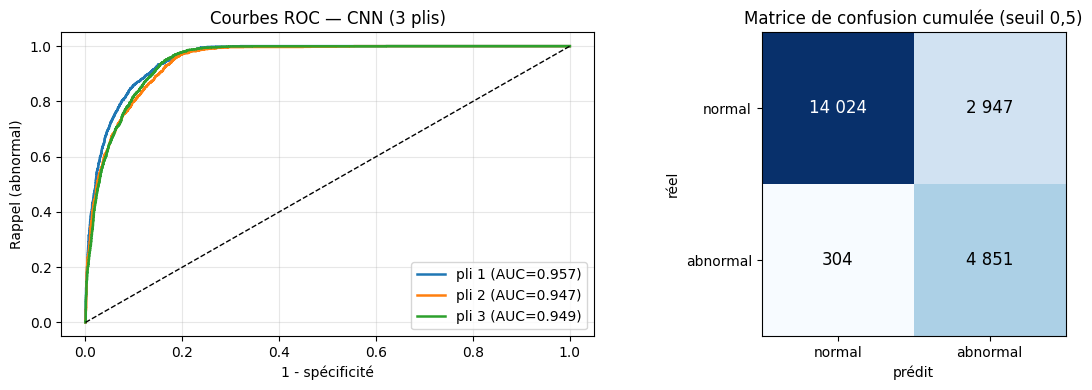

Courbes des 3 plis : c:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\plots\cnn_training_all_folds.png


In [16]:
CNN_CURVES_PLOT = plot_all_folds_training(histories, PLOT_DIR, "cnn")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for out in fold_outputs:
    fpr, tpr, _ = roc_curve(out["y_true"], out["proba"])
    axes[0].plot(fpr, tpr, lw=1.8,
                 label=f"pli {out['fold']} (AUC={roc_auc_score(out['y_true'], out['proba']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("1 - spécificité")
axes[0].set_ylabel("Rappel (abnormal)")
axes[0].set_title("Courbes ROC — CNN (3 plis)")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

cm_total = sum(confusion_matrix(out["y_true"], out["y_pred"], labels=[0, 1])
               for out in fold_outputs)
axes[1].imshow(cm_total, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm_total[i, j]:,}".replace(",", " "), ha="center", va="center",
                     color="white" if cm_total[i, j] > cm_total.max() / 2 else "black",
                     fontsize=12)
axes[1].set_xticks([0, 1], ["normal", "abnormal"])
axes[1].set_yticks([0, 1], ["normal", "abnormal"])
axes[1].set_xlabel("prédit")
axes[1].set_ylabel("réel")
axes[1].set_title("Matrice de confusion cumulée (seuil 0,5)")

fig.tight_layout()
CNN_ROC_PLOT = PLOT_DIR / "tp3_cnn_roc_confusion.png"
fig.savefig(CNN_ROC_PLOT, dpi=150)
plt.show()

print("Courbes des 3 plis :", CNN_CURVES_PLOT)


## 7. Seuil out-of-fold et évaluation agrégée

Chaque prédiction out-of-fold provient d'un modèle qui n'a **pas vu** l'enregistrement.
Le seuil est choisi sur ces prédictions (rappel maximal sous contrainte de spécificité ≥ 0,80),
puis les métriques par pli et au niveau enregistrement sont recalculées à ce seuil.


In [12]:
oof_true = np.concatenate([out["y_true"] for out in fold_outputs])
oof_proba = np.concatenate([out["proba"] for out in fold_outputs])
THRESHOLD = select_threshold(oof_true, oof_proba, min_spec=0.80)
oof_metrics = classification_metrics(oof_true, oof_proba, THRESHOLD)

for row, out in zip(fold_rows, fold_outputs):
    m = classification_metrics(out["y_true"], out["proba"], THRESHOLD)
    row.update({
        "accuracy_at_threshold": m["accuracy"],
        "balanced_accuracy_at_threshold": m["balanced_accuracy"],
        "macro_precision_at_threshold": m["macro_precision"],
        "macro_recall_at_threshold": m["macro_recall"],
        "macro_f1_at_threshold": m["macro_f1"],
        "recall_at_threshold": m["recall"],
        "specificity_at_threshold": m["specificity"],
    })

print(f"Seuil OOF = {THRESHOLD:.4f}")
print(f"OOF segment : AUC={oof_metrics['auc']:.3f} | exactitude={oof_metrics['accuracy']:.3f} | "
      f"BA={oof_metrics['balanced_accuracy']:.3f} | macro F1={oof_metrics['macro_f1']:.3f} | "
      f"rappel={oof_metrics['recall']:.3f} | spécificité={oof_metrics['specificity']:.3f}")

# --- agrégation par enregistrement (moyenne des P(abnormal) des segments du WAV)
def aggregate_by_recording(positions, probs):
    per_key = {}
    for pos, proba in zip(positions, probs):
        per_key.setdefault(keys_all[pos], []).append(float(proba))
    keys = sorted(per_key)
    return keys, np.array([np.mean(per_key[k]) for k in keys])


oof_pos = np.concatenate([fold["test_pos"] for fold in folds])
rec_keys, rec_proba = aggregate_by_recording(oof_pos, oof_proba)
y_rec = np.array([int(k[0]) for k in rec_keys])
pred_rec = (rec_proba >= THRESHOLD).astype(int)
recording_metrics = {
    "n_recordings": int(len(y_rec)),
    "accuracy": float(accuracy_score(y_rec, pred_rec)),
    "balanced_accuracy": float(balanced_accuracy_score(y_rec, pred_rec)),
    "auc": float(roc_auc_score(y_rec, rec_proba)),
    "threshold": float(THRESHOLD),
}
print(f"OOF enregistrement ({len(y_rec)} WAV) : exactitude={recording_metrics['accuracy']:.3f} | "
      f"BA={recording_metrics['balanced_accuracy']:.3f} | AUC={recording_metrics['auc']:.3f}")
for name, label in (("normal", 0), ("abnormal", 1)):
    sel = y_rec == label
    print(f"  {name:<8} : {sel.sum():>4} WAV, rappel={pred_rec[sel].mean():.3f}")


Seuil OOF = 0.3702
OOF segment : AUC=0.948 | exactitude=0.840 | BA=0.885 | macro F1=0.812 | rappel=0.971 | spécificité=0.800
OOF enregistrement (3781 WAV) : exactitude=0.751 | BA=0.828 | AUC=0.913
  normal   : 2925 WAV, rappel=0.313
  abnormal :  856 WAV, rappel=0.970


## 8. Sauvegarde du meilleur modèle TensorFlow

Le meilleur pli est choisi par l'AUC de validation. Le fichier `models/best_cnn.keras`
est rechargeable avec `tf.keras.models.load_model(path, compile=False)` et le JSON
`models/best_cnn_meta.json` contient le seuil OOF, les métriques et l'historique.


In [13]:
best_row = max(fold_rows, key=lambda row: row["roc_auc"])
best_fold = best_row["fold"]
best_model = fold_models[best_fold][0]

CNN_MODEL_PATH = MODEL_DIR / "best_cnn.keras"
CNN_META_PATH = MODEL_DIR / "best_cnn_meta.json"
best_model.save(CNN_MODEL_PATH)

meta = {
    "model": "CNN",
    "framework": "TensorFlow/Keras",
    "architecture": "build_cnn_lite",
    "file": str(CNN_MODEL_PATH),
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "threshold": float(THRESHOLD),
    "threshold_method": "rappel max sous contrainte spécificité >= 0.80 sur prédictions OOF",
    "decision": {"kind": "softmax", "aggregation": "moyenne des P(abnormal) des segments du WAV"},
    "mean_metrics": oof_metrics,
    "metrics": {"oof_segment": oof_metrics, "oof_recording": recording_metrics},
    "fold_metrics": fold_rows,
    "best_fold": int(best_fold),
    "protocol": "3 folds au niveau enregistrement (KFold(3, shuffle=True, random_state=10)), seuil OOF",
    "history_best_fold": histories[best_fold - 1]["metrics"],
    "fold_histories": {str(entry["fold"]): entry["metrics"] for entry in histories},
    "mel": {"sr": SR, "n_mels": N_MELS, "n_fft": N_FFT, "hop_length": HOP,
            "target_time_frames": T, "fmin": 20, "fmax": SR // 2,
            "downsample": DOWN, "input_shape": [INPUT_H, INPUT_W],
            "db": "power_to_db(ref=np.max)", "normalisation": "centrée-réduite par segment puis downsample"},

    "n_segments": {"total": int(len(y_all)),
                   "per_fold_validation": {str(f["fold"]): int(len(f["test_pos"])) for f in folds}},
    "n_recordings": {"total": int(len(recording_keys)),
                     "per_fold_validation": {str(f["fold"]): int(len(f["test_keys"])) for f in folds}},
    "class_counts": {"normal": int((y_all == 0).sum()), "abnormal": int((y_all == 1).sum())},
    "labels": {"0": "normal", "1": "abnormal"},
    "versions": {"tensorflow": tf.__version__, "keras": keras.__version__,
                 "librosa": librosa.__version__, "numpy": np.__version__},
    "usage": "model = tf.keras.models.load_model('models/best_cnn.keras', compile=False); "
             "proba = model.predict(mels[..., None], verbose=0)[:, 1]",
}
CNN_META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Meilleur pli : {best_fold} (AUC={best_row['roc_auc']:.3f})")
print(f"Modèle sauvegardé : {CNN_MODEL_PATH} ({CNN_MODEL_PATH.stat().st_size / 1e6:.2f} Mo)")
print(f"Métadonnées       : {CNN_META_PATH} (seuil OOF = {THRESHOLD:.3f})")


Meilleur pli : 1 (AUC=0.957)
Modèle sauvegardé : c:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_cnn.keras (5.16 Mo)
Métadonnées       : c:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_cnn_meta.json (seuil OOF = 0.370)


## 9. Suivi MLflow

Le run `cnn_mel_segments` contient les hyperparamètres, les métriques des 3 plis, les
courbes (`foldK_loss`, `foldK_val_loss`, `foldK_accuracy`, `foldK_val_accuracy`,
`foldK_val_auc`) et les artefacts (figures, CSV, poids `.keras`, métadonnées).


In [15]:
import sys
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
from mlflow_utils import log_tensorflow_run

fold_artifacts = {}
for row in fold_rows:
    fold_artifacts[str(PLOT_DIR / f"cnn_fold{row['fold']}_training.png")] = "plots"
    fold_artifacts[str(MODEL_DIR / f"cnn_fold{row['fold']}_history.csv")] = "curves"
    fold_artifacts[str(MODEL_DIR / f"cnn_fold{row['fold']}.keras")] = "models/folds"
fold_artifacts[str(CNN_CURVES_PLOT)] = "plots"
fold_artifacts[str(CNN_ROC_PLOT)] = "plots"

mlflow_params = {
    "model": "CNN",
    "framework": "TensorFlow/Keras",
    "architecture": "build_cnn_lite",
    "optimizer": "Adam(lr=1e-3)",
    "loss": "SparseCategoricalCrossentropy(poids de classes)",
    "batch_size": BS,
    "max_epochs": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "input": "Mel 128x256 normalisé puis réduit à 64x128 (channels_last)",
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP,
    "target_time_frames": T,
    "sample_rate": SR,
    "segment_seconds": pre.seg_len / pre.sr,
    "hop_seconds": pre.hop_len / pre.sr,
    "n_segments": int(len(y_all)),
    "n_recordings": int(len(recording_keys)),
    "threshold": float(THRESHOLD),
    "seed": SEED,
    "split": "3 folds au niveau enregistrement (KFold shuffle=True, random_state=10)",
    "threshold_selection": "OOF, rappel max sous contrainte spécificité >= 0.80",
}

mlflow_metrics = {key: float(oof_metrics[key]) for key in
                  ("accuracy", "balanced_accuracy", "macro_precision", "macro_recall",
                   "macro_f1", "precision", "recall", "specificity", "auc", "threshold")}
mlflow_metrics.update({
    "roc_auc": float(oof_metrics["auc"]),
    "cv_mean_auc": float(np.mean([row["roc_auc"] for row in fold_rows])),
    "cv_mean_balanced_accuracy": float(np.mean([row["balanced_accuracy"] for row in fold_rows])),
    "oof_recording_balanced_accuracy": recording_metrics["balanced_accuracy"],
    "oof_recording_auc": recording_metrics["auc"],
})

tracking_uri, run_id = log_tensorflow_run(
    run_name="cnn_mel_segments",
    model=best_model,
    params=mlflow_params,
    mean_metrics=mlflow_metrics,
    fold_metrics=fold_rows,
    histories=histories,
    artifacts={str(CNN_MODEL_PATH): "models", str(CNN_META_PATH): "models", **fold_artifacts},
    input_example=np.asarray(X_mel[folds[0]["test_pos"][:4]], dtype=np.float32).transpose(0, 2, 3, 1),
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step


2026/11/21 12:20:51 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\Admin\AppData\Local\Temp\tmpitx1qnsy\model, flavor: tensorflow). Fall back to return ['tensorflow==2.20.0', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step


2026/11/21 12:20:57 INFO mlflow.tracking._tracking_service.client: 🏃 View run cnn_mel_segments at: http://localhost:5000/#/experiments/9/runs/b17ed15d4da649e6a2eed4d14c76bc18.
2026/11/21 12:20:57 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'cnn_mel_segments' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/b17ed15d4da649e6a2eed4d14c76bc18
[MLflow] run_id = b17ed15d4da649e6a2eed4d14c76bc18


### Architecture du modèle CNN TensorFlow

| Couche | Architecture | Dimension de sortie | Paramètres |
|---|---|---:|---:|
| Entrée | Input | (B, 64, 128, 1) | 0 |
| Bloc 1 | Conv2D (1 → 32, 3×3) + BatchNorm + ReLU + MaxPool | (B, 32, 64, 32) | 352 |
| Bloc 2 | Conv2D (32 → 64, 3×3) + BatchNorm + ReLU + MaxPool + Dropout (0.1) | (B, 16, 32, 64) | 18 560 |
| Bloc 3 | Conv2D (64 → 128, 3×3) + BatchNorm + ReLU + MaxPool + Dropout (0.2) | (B, 8, 16, 128) | 73 984 |
| Bloc 4 | Conv2D (128 → 256, 3×3) + BatchNorm + ReLU + MaxPool + Dropout (0.3) | (B, 4, 8, 256) | 295 424 |
| Pooling | GlobalAveragePooling2D | (B, 256) | 0 |
| FC1 | Dense (256 → 128) + ReLU + Dropout (0.3) | (B, 128) | 32 896 |
| FC2 | Dense (128 → 2) + Softmax | (B, 2) | 258 |

**Nombre total de paramètres entraînables : 421 474**

Les couches Conv2D extraient les motifs temps-fréquence du Mel, BatchNorm stabilise
l'entraînement, MaxPooling réduit la dimension, Dropout limite le surapprentissage et
la sortie Softmax fournit P(normal) / P(abnormal) pour chaque segment.
